In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df= pd.read_csv('movies_metadata.csv')

In [3]:
df.columns

Index(['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id',
       'imdb_id', 'original_language', 'original_title', 'overview',
       'popularity', 'poster_path', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'video',
       'vote_average', 'vote_count'],
      dtype='str')

In [4]:
df.isnull().sum()

adult                        0
belongs_to_collection    40972
budget                       0
genres                       0
homepage                 37684
id                           0
imdb_id                     17
original_language           11
original_title               0
overview                   954
popularity                   5
poster_path                386
production_companies         3
production_countries         3
release_date                87
revenue                      6
runtime                    263
spoken_languages             6
status                      87
tagline                  25054
title                        6
video                        6
vote_average                 6
vote_count                   6
dtype: int64

In [5]:
df = df.drop(columns = ['homepage','belongs_to_collection'])

In [6]:
df.duplicated().sum()

np.int64(13)

In [7]:
df = df.drop_duplicates()

In [8]:
df = df[[
    'id',
    'title',
    'genres',
    'overview',
    'tagline',
    'original_language',
    'vote_average',
    'vote_count',
    'popularity'
]]

In [9]:
df.isnull().sum()

id                       0
title                    6
genres                   0
overview               954
tagline              25045
original_language       11
vote_average             6
vote_count               6
popularity               5
dtype: int64

In [10]:
df.shape

(45453, 9)

In [11]:
df= df.dropna(subset=['title'])   #empty title must be dropped

In [12]:
df['popularity'].head()

0    21.946943
1    17.015539
2      11.7129
3     3.859495
4     8.387519
Name: popularity, dtype: object

In [13]:
df['overview'] = df['overview'].fillna('')
df['tagline'] = df['tagline'].fillna('')
df['original_language'] = df['original_language'].fillna('unknown')

In [14]:
import ast

def extract_names(value):
    try:
        genre_list = ast.literal_eval(value)
        genre_names = []
        
        for i in genre_list:
            genre_names.append(i['name'])
        
        return genre_names
        
    except (ValueError, SyntaxError, TypeError):
        return []

df["genres"] = df["genres"].apply(extract_names)

In [15]:
df['genres'].head()

0     [Animation, Comedy, Family]
1    [Adventure, Fantasy, Family]
2               [Romance, Comedy]
3        [Comedy, Drama, Romance]
4                        [Comedy]
Name: genres, dtype: object

In [16]:
df= df.drop(columns = ['id'])

In [17]:
df.head()

,title,genres,overview,tagline,original_language,vote_average,vote_count,popularity
0,Toy Story,"[Animation, Comedy, Family]","Led by Woody, Andy's toys live happily in his ...",,en,7.7,5415.0,21.946943
1,Jumanji,"[Adventure, Fantasy, Family]",When siblings Judy and Peter discover an encha...,Roll the dice and unleash the excitement!,en,6.9,2413.0,17.015539
2,Grumpier Old Men,"[Romance, Comedy]",A family wedding reignites the ancient feud be...,Still Yelling. Still Fighting. Still Ready for...,en,6.5,92.0,11.7129
3,Waiting to Exhale,"[Comedy, Drama, Romance]","Cheated on, mistreated and stepped on, the wom...",Friends are the people who let you be yourself...,en,6.1,34.0,3.859495
4,Father of the Bride Part II,[Comedy],Just when George Banks has recovered from his ...,Just When His World Is Back To Normal... He's ...,en,5.7,173.0,8.387519


<Axes: xlabel='popularity', ylabel='Count'>

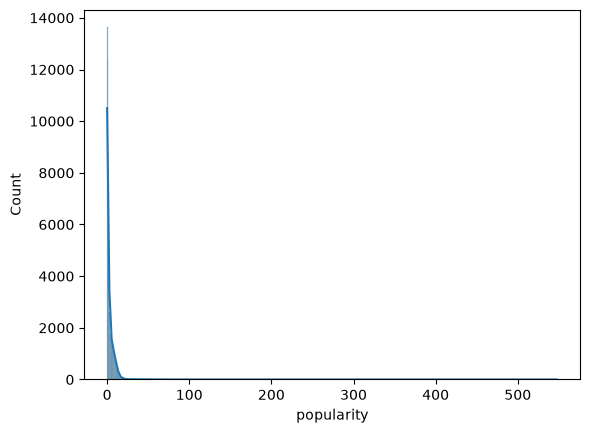

In [18]:
sns.histplot(df['popularity'],kde = True)

this histplot looks like i have an outlier 

In [19]:
df['popularity'].describe()

count     45447
unique    44175
top         0.0
freq         34
Name: popularity, dtype: object

the column popularity has dtype object and contains str values and numeric values together. i gotta fix that

In [20]:
bad = df[pd.to_numeric(df['popularity'], errors='coerce').isna()]
print(bad[['title', 'popularity']])

Empty DataFrame
Columns: [title, popularity]
Index: []


In [21]:
df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')

In [22]:
df = df.dropna(subset=['popularity'])

In [23]:
print(df['popularity'].dtype)    # should say float64
df.sort_values('popularity', ascending=False)[['title', 'popularity']].head(10)

float64


,title,popularity
30700,Minions,547.488298
33356,Wonder Woman,294.337037
42222,Beauty and the Beast,287.253654
43644,Baby Driver,228.032744
24455,Big Hero 6,213.849907
26564,Deadpool,187.860492
26566,Guardians of the Galaxy Vol. 2,185.330992
14551,Avatar,185.070892
24351,John Wick,183.870374
23675,Gone Girl,154.801009


well , those are valid outliers , so i ain't gonna touch them

<Axes: xlabel='vote_average', ylabel='Count'>

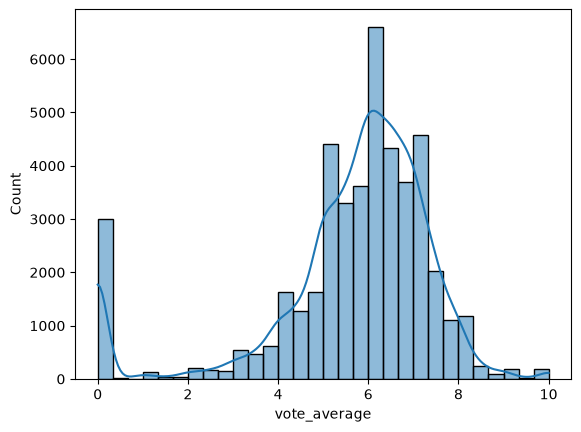

In [24]:
sns.histplot(df['vote_average'],bins=30,kde=True)

In [25]:
df = df.reset_index(drop=True)

In [26]:
df

,title,genres,overview,tagline,original_language,vote_average,vote_count,popularity
0,Toy Story,"[Animation, Comedy, Family]","Led by Woody, Andy's toys live happily in his ...",,en,7.7,5415.0,21.946943
1,Jumanji,"[Adventure, Fantasy, Family]",When siblings Judy and Peter discover an encha...,Roll the dice and unleash the excitement!,en,6.9,2413.0,17.015539
2,Grumpier Old Men,"[Romance, Comedy]",A family wedding reignites the ancient feud be...,Still Yelling. Still Fighting. Still Ready for...,en,6.5,92.0,11.712900
3,Waiting to Exhale,"[Comedy, Drama, Romance]","Cheated on, mistreated and stepped on, the wom...",Friends are the people who let you be yourself...,en,6.1,34.0,3.859495
4,Father of the Bride Part II,[Comedy],Just when George Banks has recovered from his ...,Just When His World Is Back To Normal... He's ...,en,5.7,173.0,8.387519
...,...,...,...,...,...,...,...,...
45442,Subdue,"[Drama, Family]",Rising and falling between a man and woman.,Rising and falling between a man and woman,fa,4.0,1.0,0.072051
45443,Century of Birthing,[Drama],An artist struggles to finish his work while a...,,tl,9.0,3.0,0.178241
45444,Betrayal,"[Action, Drama, Thriller]","When one of her hits goes wrong, a professiona...",A deadly game of wits.,en,3.8,6.0,0.903007
45445,Satan Triumphant,[],"In a small town live two brothers, one a minis...",,en,0.0,0.0,0.003503


i just saw movies with genre []

In [27]:
empty_mask = df['genres'].apply(len) == 0
print(empty_mask.sum(), "movies with no genre")

# i am just gonna drop them 

2442 movies with no genre


In [28]:
df = df[df['genres'].apply(len) > 0].reset_index(drop= True)

In [29]:
df.shape

(43005, 8)

NOW I AM GONNA ONE HOT ENCODE THE GENRES WITH MULTI LABEL BINARIZER

In [30]:
from sklearn.preprocessing import MultiLabelBinarizer

In [31]:
mlb = MultiLabelBinarizer()

In [32]:
genre_matrix = mlb.fit_transform(df['genres'])

In [33]:
genre_df = pd.DataFrame(genre_matrix, columns=mlb.classes_ , index=df.index)

In [34]:
genre_df

,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,Foreign,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
43001,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0
43002,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0
43003,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [35]:
df = pd.concat([df.drop(columns = ['genres']), genre_df], axis=1)

In [37]:
df.head(3)

,title,overview,tagline,original_language,vote_average,vote_count,popularity,Action,Adventure,Animation,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,Toy Story,"Led by Woody, Andy's toys live happily in his ...",,en,7.7,5415.0,21.946943,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,Jumanji,When siblings Judy and Peter discover an encha...,Roll the dice and unleash the excitement!,en,6.9,2413.0,17.015539,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,Grumpier Old Men,A family wedding reignites the ancient feud be...,Still Yelling. Still Fighting. Still Ready for...,en,6.5,92.0,11.712900,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [38]:
df.to_csv('final_data.csv',index=False)